# Choosing one training target per identity

`Facial` maps **N frames of a person onto a single image**, so training it needs one target
image per identity. This notebook picks that frame.

Two things decide which frame is a good target:

1. **How well a recogniser identifies it.** The target is the best the reconstruction can
   ever be, so a mediocre target caps the whole model.
2. **Pose, consistently across identities.** `FacialAggregator` pools with a *fixed* learned
   query, so nothing tells the decoder which pose to produce. If the targets point in all
   directions the decoder can only learn their average, which is a blurry face.

Those two are nearly independent (measured: Spearman 0.09), so we use both: shortlist the
frames the recogniser identifies best, then take the most frontal one of those.

The ArcFace embedding norm, which the earlier notebook used, turns out to measure neither
— selecting on it is no better than picking a frame at random.

In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

from meles.detection import ARCFACE_TEMPLATE, default_detector, umeyama
from meles.embedding_aggregation import normalized
from meles.frame_embedder import FrameEmbedder, models

DATA_PATH = Path("../../data")
SHORTLIST = 50  # frames per identity kept after the identifiability ranking

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
structure = pd.read_parquet(DATA_PATH / "ytfaces_all.parquet")
structure

,identity,video,frame,frame_suffix,path
0,Alexa_Vega,1,aligned_detect_1.470.jpg,.jpg,ytfaces/Alexa_Vega/1/aligned_detect_1.470.jpg
1,Alexa_Vega,1,aligned_detect_1.689.jpg,.jpg,ytfaces/Alexa_Vega/1/aligned_detect_1.689.jpg
2,Alexa_Vega,1,aligned_detect_1.721.jpg,.jpg,ytfaces/Alexa_Vega/1/aligned_detect_1.721.jpg
3,Alexa_Vega,1,aligned_detect_1.634.jpg,.jpg,ytfaces/Alexa_Vega/1/aligned_detect_1.634.jpg
4,Alexa_Vega,1,aligned_detect_1.197.jpg,.jpg,ytfaces/Alexa_Vega/1/aligned_detect_1.197.jpg
...,...,...,...,...,...
621121,Fred_Thompson,1,aligned_detect_1.378.jpg,.jpg,ytfaces/Fred_Thompson/1/aligned_detect_1.378.jpg
621122,Fred_Thompson,1,aligned_detect_1.358.jpg,.jpg,ytfaces/Fred_Thompson/1/aligned_detect_1.358.jpg
621123,Fred_Thompson,1,aligned_detect_1.357.jpg,.jpg,ytfaces/Fred_Thompson/1/aligned_detect_1.357.jpg
621124,Fred_Thompson,1,aligned_detect_1.376.jpg,.jpg,ytfaces/Fred_Thompson/1/aligned_detect_1.376.jpg


In [3]:
from meles.dataset import truncate_dataset

MIN_VIDEOS_PER_IDENTITY = 2  # drop identities with fewer than this many videos
MAX_FRAMES_PER_VIDEO = 75  # keep only the first N frames of each video

structure = truncate_dataset(structure, MIN_VIDEOS_PER_IDENTITY, MAX_FRAMES_PER_VIDEO)
structure

,identity,video,frame,frame_suffix,path
0,AJ_Cook,0,aligned_detect_0.123.jpg,.jpg,ytfaces/AJ_Cook/0/aligned_detect_0.123.jpg
1,AJ_Cook,0,aligned_detect_0.124.jpg,.jpg,ytfaces/AJ_Cook/0/aligned_detect_0.124.jpg
2,AJ_Cook,0,aligned_detect_0.125.jpg,.jpg,ytfaces/AJ_Cook/0/aligned_detect_0.125.jpg
3,AJ_Cook,0,aligned_detect_0.126.jpg,.jpg,ytfaces/AJ_Cook/0/aligned_detect_0.126.jpg
4,AJ_Cook,0,aligned_detect_0.127.jpg,.jpg,ytfaces/AJ_Cook/0/aligned_detect_0.127.jpg
...,...,...,...,...,...
195846,Zulfiqar_Ahmed,4,aligned_detect_4.225.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.225.jpg
195847,Zulfiqar_Ahmed,4,aligned_detect_4.226.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.226.jpg
195848,Zulfiqar_Ahmed,4,aligned_detect_4.227.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.227.jpg
195849,Zulfiqar_Ahmed,4,aligned_detect_4.228.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.228.jpg


## 1. Embed every frame

One ArcFace embedding per frame. This is the slow step (~15 min for 130k frames), so the
result is cached next to the dataset.

In [4]:
EMBEDDINGS_PATH = DATA_PATH / "ytfaces_embeddings.parquet"

if EMBEDDINGS_PATH.exists():
    structure = pd.read_parquet(EMBEDDINGS_PATH)
else:
    arcface = FrameEmbedder(models.ARCFACE)
    structure["embedding"] = arcface.embed([str(DATA_PATH / path) for path in structure["path"]])
    structure.to_parquet(EMBEDDINGS_PATH, index=False)

# Unit vectors, so every comparison below is a plain cosine. Normalising matters: without it
# the long vectors dominate and we would be ranking by embedding norm again.
unit = np.asarray(normalized(np.stack(structure["embedding"].apply(np.asarray).values)), dtype=np.float32)
unit.shape

Embedding (ArcFace): 100%|██████████| 195851/195851 [19:32<00:00, 166.99frame/s]


(195851, 512)

## 2. How well is each frame identified?

Score every frame the way the experiment's classifier would, as a **margin**:

    margin = similarity to its own identity  -  similarity to the closest other identity

The "own identity" half is computed against that identity's **other videos only**.
Neighbouring frames of one shot are near-duplicates, so comparing a frame against its own
video would measure redundancy rather than identifiability — the same trap the fold split
exists to avoid.

In [5]:
identities = np.array(sorted(structure["identity"].unique()))
identity_of = structure["identity"].values
video_of = structure["video"].values

# The gallery an attacker would hold: one mean embedding per identity.
gallery = np.stack([unit[identity_of == name].mean(axis=0) for name in identities])
gallery /= np.linalg.norm(gallery, axis=1, keepdims=True)

# Genuine similarity, leaving the frame's own video out of its identity's centroid.
genuine = np.zeros(len(structure), dtype=np.float32)
for name in tqdm(identities, desc="genuine similarity"):
    rows = identity_of == name
    for video in np.unique(video_of[rows]):
        centroid = unit[rows & (video_of != video)].mean(axis=0)
        held_out = rows & (video_of == video)
        genuine[held_out] = unit[held_out] @ (centroid / np.linalg.norm(centroid))

# Impostor similarity: the best match among all the other identities.
similarity = unit @ gallery.T
similarity[np.arange(len(structure)), np.searchsorted(identities, identity_of)] = -np.inf

structure["margin"] = genuine - similarity.max(axis=1)
structure["margin"].describe()

genuine similarity: 100%|██████████| 1004/1004 [00:15<00:00, 63.12it/s]


count    195851.000000
mean          0.320092
std           0.196072
min          -0.768293
25%           0.219382
50%           0.351653
75%           0.458263
max           0.810265
Name: margin, dtype: float64

## 3. How frontal is each frame?

`umeyama` fits a **similarity** transform — rotation, uniform scale, translation — from the
five detected landmarks onto `ARCFACE_TEMPLATE`, which is the canonical *frontal* layout. A
similarity transform cannot represent out-of-plane rotation, so whatever error is left after
the best fit *is* the yaw and pitch. Lower is more frontal.

This needs a detection pass, so we only run it on the shortlist rather than all 130k frames.

In [6]:
def frontality(landmarks):
    """RMS distance to the frontal template after the best similarity fit, in template pixels."""
    matrix = umeyama(landmarks, ARCFACE_TEMPLATE)
    aligned = landmarks @ matrix[:, :2].T + matrix[:, 2]
    return float(np.sqrt(((aligned - ARCFACE_TEMPLATE) ** 2).sum(axis=1).mean()))


# The frames the recogniser identifies best, per identity.
shortlist = structure.sort_values("margin", ascending=False).groupby("identity").head(SHORTLIST).copy()

residuals = []
for path in tqdm(shortlist["path"], desc="frontality"):
    area = default_detector.detect_best(cv2.imread(str(DATA_PATH / path)))
    # A frame without landmarks sorts last rather than being dropped.
    residuals.append(frontality(np.asarray(area.landmarks, dtype=np.float64))
                     if area is not None and area.landmarks is not None else np.inf)

shortlist["residual"] = residuals
shortlist["residual"].describe()

frontality: 100%|██████████| 50200/50200 [04:36<00:00, 181.70it/s]
/data/projects/personal/meles/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    5.020000e+04
mean              inf
std               NaN
min      3.972862e-01
25%      2.487662e+00
50%      3.089575e+00
75%      3.806906e+00
max               inf
Name: residual, dtype: float64

## 4. Pick the target

The most frontal frame of each identity's shortlist.

In [7]:
targets = shortlist.loc[shortlist.groupby("identity")["residual"].idxmin()].reset_index(drop=True)

print(f"targets:            {len(targets):>8,}")
print(f"mean margin:        {targets['margin'].mean():>8.3f}   (all frames: {structure['margin'].mean():.3f})")
print(f"mean residual:      {targets['residual'].mean():>8.3f} px")
print(f"residual spread SD: {targets['residual'].std():>8.3f} px")

targets.drop(columns="embedding").head()

targets:               1,004
mean margin:           0.378   (all frames: 0.320)
mean residual:         1.801 px
residual spread SD:    0.709 px


,identity,video,frame,frame_suffix,path,margin,residual
0,AJ_Cook,0,aligned_detect_0.194.jpg,.jpg,ytfaces/AJ_Cook/0/aligned_detect_0.194.jpg,0.229059,1.001498
1,Aaron_Eckhart,0,aligned_detect_0.555.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.555.jpg,0.379302,2.512482
2,Aaron_Sorkin,3,aligned_detect_3.458.jpg,.jpg,ytfaces/Aaron_Sorkin/3/aligned_detect_3.458.jpg,-0.263898,1.161527
3,Aaron_Tippin,0,aligned_detect_0.448.jpg,.jpg,ytfaces/Aaron_Tippin/0/aligned_detect_0.448.jpg,0.201911,1.043052
4,Abba_Eban,0,aligned_detect_0.94.jpg,.jpg,ytfaces/Abba_Eban/0/aligned_detect_0.94.jpg,0.507657,2.389572


Both numbers should have moved the right way: a higher margin than the dataset average means
the targets are easier to identify, and a small residual spread means they share a pose.

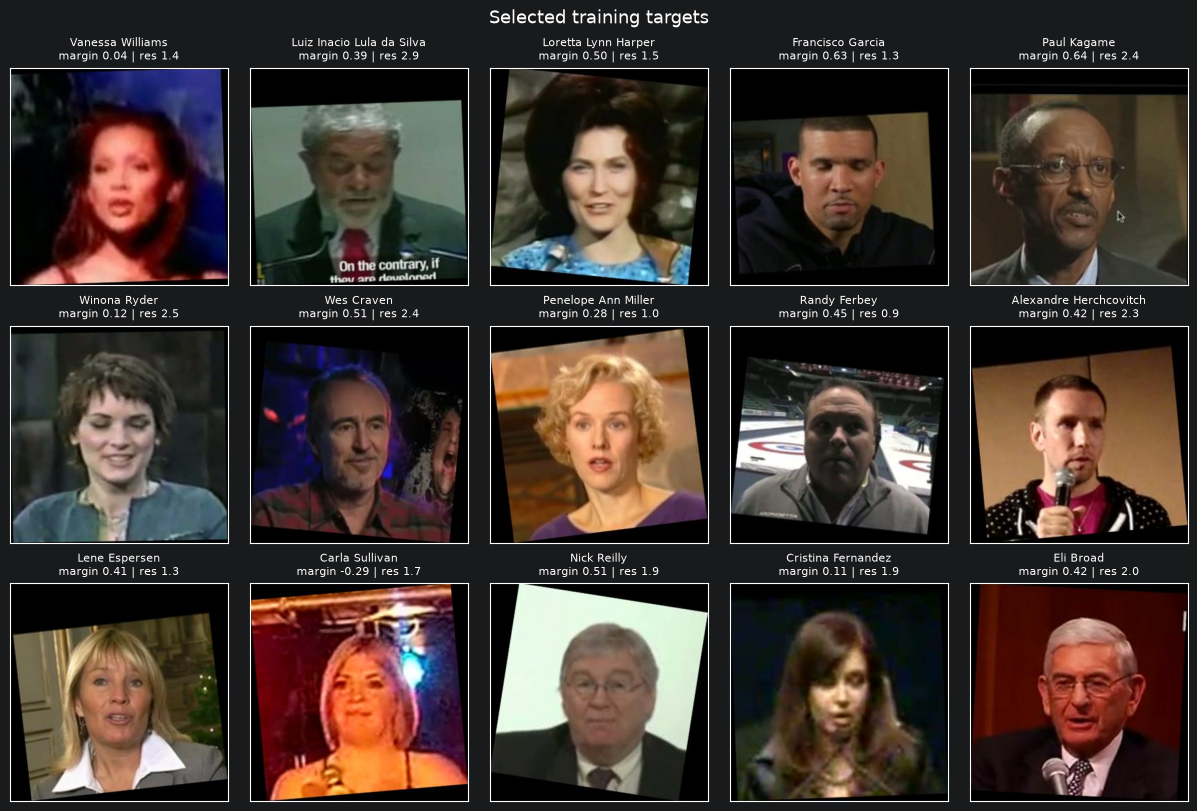

In [8]:
N_SHOWN = 15

sample = targets.sample(n=N_SHOWN, random_state=1)

fig, axes = plt.subplots(3, 5, figsize=(12, 8), layout="constrained")
for ax, (_, target) in zip(axes.flat, sample.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA_PATH / target["path"])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{target['identity'].replace('_', ' ')}\nmargin {target['margin']:.2f} | res {target['residual']:.1f}",
                 fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Selected training targets", fontsize=13)
plt.show()

## 5. Save

One row per identity, pointing at the frame to use as that identity's target.

In [9]:
targets.drop(columns="embedding").to_parquet(DATA_PATH / "ytfaces_targets.parquet", index=False)

In [11]:
structure.to_parquet(DATA_PATH / "ytfaces_values.parquet", index=False)

# The same frames without the embedding column: the structure 06_facial trains on. It cannot be
# written back to 'ytfaces.parquet' -- workflow/config.yaml names that file as the Snakemake
# dataset, so widening it in place would silently redefine the sweep's identity set.
structure.drop(columns=[c for c in ("embedding", "margin") if c in structure]).to_parquet(
    DATA_PATH / "ytfaces_wide.parquet", index=False
)